**CCGT Case Study 1: Ambient Temperature**

A gas turbine is a constant volume machine: its compressor draws about the same volumetric flow whatever the weather. On a hot day the air is less dense, so the mass flow, and with it the power, falls. This notebook quantifies the classic **derating curve** of the combined cycle with the off-design model:

* the HRSG areas are frozen at their design values (UA), so the steam flow, steam temperature and stack temperature float;
* the compressor draws its design volumetric flow, and the turbine's swallowing capacity ($\dot m\sqrt{T}/P$ constant, a choked first stage nozzle) sets the pressure ratio;
* the turbine inlet temperature is held at 1350 °C (full load);
* the condenser pressure is either fixed at 0.08 bar or follows ambient (saturation temperature 26.5 K above ambient, as a cooling system with a constant temperature rise).

In [1]:
import idaes

print("IDAES version: ", idaes.__version__)

IDAES version:  2.13.0


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from ccgt import setup_ccgt_model, set_mode, ccgt_results
from ccgt_case_studies import solve

pd.set_option("display.max_columns", 40)

# Design point (DWSIM specifications), then the design targets (TIT 1350 C, 10 K pinch)
model, results = setup_ccgt_model()
set_mode(model, "targets")
solve(model)
# Off-design: HRSG areas frozen at their design values, compressor volumetric flow and turbine swallowing capacity fixed
set_mode(model, "offdesign")
solve(model)
design = ccgt_results(model)
print("Net power {0:.0f} kW, efficiency {1:.2f} %".format(design["Plant net power (kW)"],
                                                          design["Combined cycle efficiency LHV (%)"]))

2026-11-12 16:51:06 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:51:06 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:51:06 [WARNING] idaes.models.properties.general_helmholtz.helmholtz_state: Helmholtz EoS packages using Mixed phase representation ignore the 'has_phase_equilibrium' configuration argument. However, setting this to True can result in errors when constructing material balances due to only having a single phase (thus phase transfer terms cannot be constructed).


2026-11-12 16:51:06 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.control_volume.properties_in[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


2026-11-12 16:51:06 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.control_volume.properties_out[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


2026-11-12 16:51:06 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.compressor.properties_isentropic[0.0].enth_mol_phase[Vap], for _enthalpy_flow_term


... (43 outputs left out)

2026-11-12 16:51:06 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.economizer.cold_side.heat


2026-11-12 16:51:06 [WARNING] idaes.core.util.scaling: Missing scaling factor for fs.condenser.control_volume.heat


The DOF is 0


Net power 27113 kW, efficiency 56.08 %


## Ambient temperature sweep, 0–45 °C

Each point is warm started from the previous one (continuation).

In [3]:
from ccgt_case_studies import ambient_sweep

fixed = ambient_sweep(model)
follows = ambient_sweep(model, condenser_follows_ambient=True)
cols = ["Plant net power (kW)", "Gas turbine net (kW)", "Steam turbine (kW)", "Combined cycle efficiency LHV (%)",
        "Heat rate LHV (kJ/kWh)", "Air flow (kg/s)", "Pressure ratio", "GT exhaust temperature (C)",
        "Steam flow (kg/s)", "Steam temperature (C)", "Stack temperature (C)", "Condenser pressure (bar)"]
follows[cols].round(2)

,Plant net power (kW),Gas turbine net (kW),Steam turbine (kW),Combined cycle efficiency LHV (%),Heat rate LHV (kJ/kWh),Air flow (kg/s),Pressure ratio,GT exhaust temperature (C),Steam flow (kg/s),Steam temperature (C),Stack temperature (C),Condenser pressure (bar)
Ambient temperature (C),,,,,,,,,,,,
0,30009.46,20654.18,9420.16,57.46,6264.72,42.21,17.93,657.42,8.20,489.77,99.76,0.03
5,29007.45,19946.27,9125.41,57.01,6314.80,41.44,17.61,660.63,8.11,493.19,101.38,0.05
10,28042.68,19268.12,8838.15,56.55,6366.41,40.71,17.30,663.80,8.02,496.60,103.12,0.06
15,27113.26,18618.04,8558.20,56.08,6419.59,40.00,17.00,666.92,7.93,500.00,104.99,0.08
20,26217.43,17994.45,8285.35,55.60,6474.41,39.32,16.71,670.00,7.84,503.39,106.97,0.10
25,25353.56,17395.91,8019.44,55.12,6530.89,38.65,16.43,673.03,7.75,506.77,109.07,0.13
30,24520.09,16821.05,7760.26,54.64,6589.08,38.01,16.17,676.03,7.67,510.14,111.27,0.17
35,23715.59,16268.61,7507.64,54.14,6649.05,37.40,15.91,678.98,7.58,513.49,113.58,0.21
40,22938.71,15737.42,7261.39,53.64,6710.85,36.80,15.65,681.90,7.50,516.84,115.99,0.27


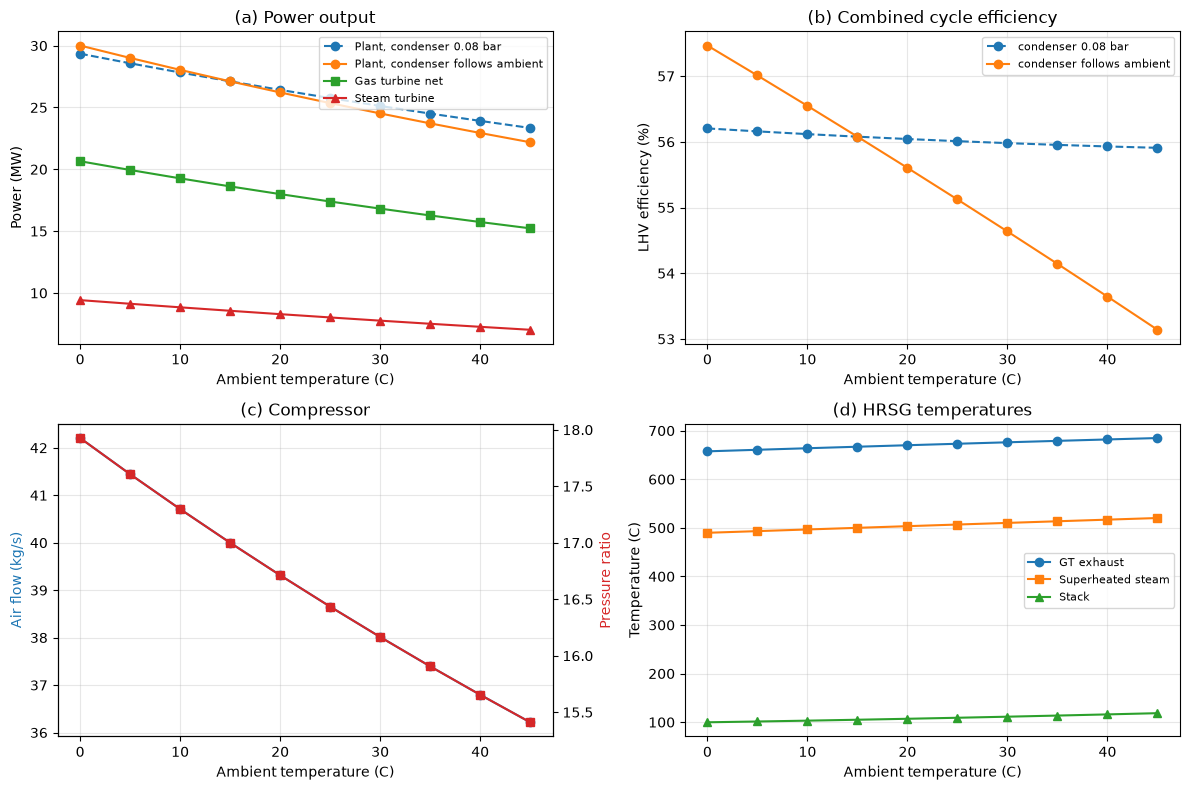

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ax = axes[0, 0]
for df, style, label in ((fixed, "o--", "condenser 0.08 bar"), (follows, "o-", "condenser follows ambient")):
    ax.plot(df.index, df["Plant net power (kW)"] / 1e3, style, label="Plant, " + label)
ax.plot(follows.index, follows["Gas turbine net (kW)"] / 1e3, "s-", label="Gas turbine net")
ax.plot(follows.index, follows["Steam turbine (kW)"] / 1e3, "^-", label="Steam turbine")
ax.set_ylabel("Power (MW)")
ax.set_title("(a) Power output")
ax.legend(fontsize=8)

ax = axes[0, 1]
for df, style, label in ((fixed, "o--", "condenser 0.08 bar"), (follows, "o-", "condenser follows ambient")):
    ax.plot(df.index, df["Combined cycle efficiency LHV (%)"], style, label=label)
ax.set_ylabel("LHV efficiency (%)")
ax.set_title("(b) Combined cycle efficiency")
ax.legend(fontsize=8)

ax = axes[1, 0]
ax.plot(follows.index, follows["Air flow (kg/s)"], "o-", color="tab:blue")
ax.set_ylabel("Air flow (kg/s)", color="tab:blue")
ax2 = ax.twinx()
ax2.plot(follows.index, follows["Pressure ratio"], "s-", color="tab:red")
ax2.set_ylabel("Pressure ratio", color="tab:red")
ax.set_title("(c) Compressor")

ax = axes[1, 1]
ax.plot(follows.index, follows["GT exhaust temperature (C)"], "o-", label="GT exhaust")
ax.plot(follows.index, follows["Steam temperature (C)"], "s-", label="Superheated steam")
ax.plot(follows.index, follows["Stack temperature (C)"], "^-", label="Stack")
ax.set_ylabel("Temperature (C)")
ax.set_title("(d) HRSG temperatures")
ax.legend(fontsize=8)
for ax in axes.flat:
    ax.set_xlabel("Ambient temperature (C)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**What the curves show**

* **Power falls by about 0.5–0.6 % of the ISO rating per K.** From 0 to 45 °C the air mass flow drops by about 14 % (density), and the pressure ratio falls with it, because the turbine swallows less mass at the same inlet temperature. Both the gas turbine and the steam turbine lose output.
* **The efficiency barely changes if the condenser pressure is fixed.** The gas turbine is a little less efficient on a hot day, but its hotter exhaust raises more and hotter steam, which nearly compensates. With a realistic cooling system the condenser pressure rises on hot days (0.03 → 0.33 bar), and the efficiency falls by about 4 points from 0 to 45 °C.
* **Off-design HRSG:** with fixed areas, the steam temperature rises on hot days (hotter exhaust, less gas), and on cold days the economizer approaches saturation. Plants protect against both, with attemperators and economizer recirculation.

## Seasonal output

The ambient curve gives the monthly output for a site's monthly mean temperatures. The example below uses a hot climate with a summer peak. Inlet air cooling (evaporative coolers or chillers), which lowers the compressor inlet temperature in summer, is the usual remedy.

In [5]:
from ccgt_case_studies import seasonal_output

monthly_T = {"Jan": 14, "Feb": 16, "Mar": 20, "Apr": 25, "May": 30, "Jun": 34,
             "Jul": 36, "Aug": 35, "Sep": 32, "Oct": 27, "Nov": 21, "Dec": 16}
season = seasonal_output(follows, monthly_T, availability=0.95)
print("Annual energy {0:,.0f} MWh, average output {1:.2f} MW".format(season["Energy (MWh)"].sum(),
                                                                     season["Net power (MW)"].mean()))
season.round(2)

Annual energy 210,598 MWh, average output 25.31 MW


,Ambient (C),Net power (MW),Efficiency (%),Energy (MWh)
Month,,,,
Jan,14,27.30,56.17,18931.96
Feb,16,26.93,55.98,18678.80
Mar,20,26.22,55.60,18181.79
Apr,25,25.35,55.12,17582.69
May,30,24.52,54.64,17004.68
Jun,34,23.88,54.24,16558.35
Jul,36,23.56,54.04,16339.01
Aug,35,23.72,54.14,16446.76
Sep,32,24.20,54.44,16781.52


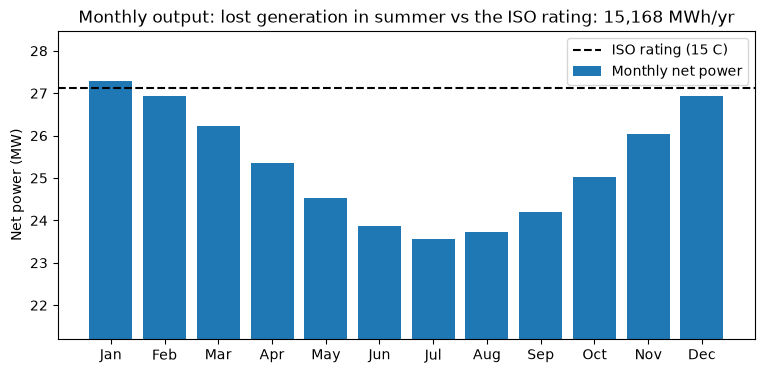

In [6]:
T_iso = 15.0
p_iso = follows.loc[T_iso, "Plant net power (kW)"] / 1e3
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(season.index, season["Net power (MW)"], color="tab:blue", label="Monthly net power")
ax.axhline(p_iso, color="k", ls="--", label="ISO rating (15 C)")
ax.set_ylabel("Net power (MW)")
ax.set_ylim(season["Net power (MW)"].min() * 0.9, p_iso * 1.05)
ax.legend()
ax.set_title("Monthly output: lost generation in summer vs the ISO rating: {0:,.0f} MWh/yr".format(
    (p_iso - season["Net power (MW)"]).clip(lower=0).mul(730 * 0.95).sum()))
plt.show()